**Name:** Ibrahim Khaled Al-Khamis

**Id:** 2240004075

**Section:** 7MA01

**Course:**   ARTI 403 – Image Processing

---
# Lab 6:   Frequency Domain

### Task 1: Apply the Sobel filter(s) in the frequency domain and show the results.

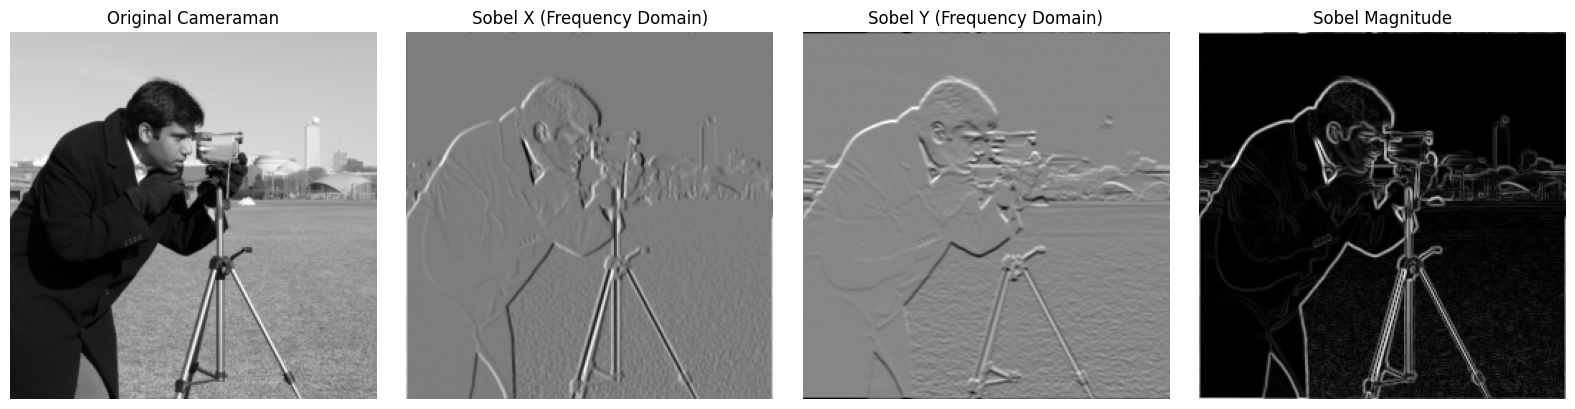

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize
from numpy.fft import fft2, ifft2, ifftshift

image = cv2.imread('cameraman.tif', cv2.IMREAD_GRAYSCALE)
image = resize(image, (256, 256))

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0, 0, 0],
                    [ 1, 2, 1]])

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))

F = fft2(image)

F_sobel_x = center_embed_kernel(sobel_x, image.shape)
F_sobel_y = center_embed_kernel(sobel_y, image.shape)

F_out_x = F * F_sobel_x
F_out_y = F * F_sobel_y

sobel_x_image = ifft2(F_out_x).real
sobel_y_image = ifft2(F_out_y).real

magnitude = np.sqrt(sobel_x_image**2 + sobel_y_image**2)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_x_image, cmap='gray')
plt.title('Sobel X (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(sobel_y_image, cmap='gray')
plt.title('Sobel Y (Frequency Domain)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(magnitude, cmap='gray')
plt.title('Sobel Magnitude')
plt.axis('off')

plt.tight_layout()
plt.show()

---